# 09 · BI, benchmark và fault test

- Superset nối HiveServer2, có dashboard 5 chart.
- Grafana đọc Prometheus (Kafka, HDFS, Spark, stream).
- Benchmark CSV vs Parquet, có/không partition, Hive vs Spark SQL.
- Fault test: dừng HiveServer2, DataNode, Kafka rồi khôi phục.

In [1]:
import json
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ART = ROOT / "artifacts"
REPORTS = ROOT / "reports"

def sh(command, timeout=600):
    result = subprocess.run(command, capture_output=True, text=True, timeout=timeout)
    return result.stdout + result.stderr

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else {}

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
GREEN, TEAL, GOLD, RED = "#1F6B45", "#2B6E7A", "#8F5E1A", "#A23B2A"

## 1. BI đang sống

In [2]:
import requests
for name, url in [("Superset", "http://localhost:8088/health"),
                  ("Grafana", "http://localhost:3000/api/health"),
                  ("Airflow", "http://localhost:8085/health")]:
    try:
        print(name, requests.get(url, timeout=5).status_code)
    except Exception as exc:
        print(name, "unreachable:", exc)
print("Superset dashboard: http://localhost:8088/superset/dashboard/1/")
print("Grafana dashboard: http://localhost:3000/d/agri-dwh-overview")

Superset 200
Grafana 200
Airflow 200
Superset dashboard: http://localhost:8088/superset/dashboard/1/
Grafana dashboard: http://localhost:3000/d/agri-dwh-overview


## 2. Benchmark

,engine,source,scale,query,seconds_median,result_rows
0,hive,parquet_partitioned,100000,count_all,19.494,1
1,hive,parquet_partitioned,100000,avg_yield_by_location,20.625,12
2,hive,parquet_partitioned,100000,avg_soil_when_hot,19.811,12
3,hive,parquet_partitioned,100000,top10_yield,20.422,10
4,hive,parquet_partitioned,1052064,count_all,17.711,1
5,hive,parquet_partitioned,1052064,avg_yield_by_location,18.208,12
6,hive,parquet_partitioned,1052064,avg_soil_when_hot,24.144,12
7,hive,parquet_partitioned,1052064,top10_yield,31.773,10
8,spark_sql,parquet_partitioned,100000,count_all,3.841,1
9,spark_sql,parquet_partitioned,100000,avg_yield_by_location,3.844,12


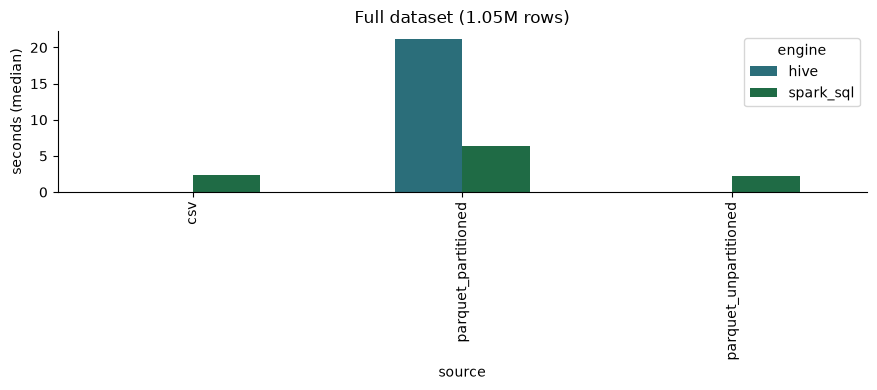

In [3]:
bench = ART / "bench" / "fullstack_benchmark.csv"
if bench.exists():
    frame = pd.read_csv(bench)
    display(frame)
    full = frame[frame["scale"] == frame["scale"].max()]
    if len(full):
        pivot = full.pivot_table(index="source", columns="engine", values="seconds_median", aggfunc="median")
        pivot.plot.bar(color=[TEAL, GREEN])
        plt.ylabel("seconds (median)")
        plt.title("Full dataset (1.05M rows)")
        plt.tight_layout(); plt.show()
else:
    print("Chưa có kết quả benchmark.")

## 3. Fault test

In [4]:
faults = read_json(REPORTS / "fault_test_fullstack.json")
if faults:
    display(pd.DataFrame(faults.get("results", [])))
else:
    print("Chưa chạy: python tests/fault_tests.py")

,scenario,before,during_outage,after_restart,recovered
0,hiveserver2 stopped and restarted,True,False,True,True
1,datanode stopped and restarted,True,False,True,True
2,kafka broker stopped and restarted,True,False,True,True


## 4. Tổng kết

In [5]:
summary = REPORTS / "final_summary_fullstack.md"
print(summary.read_text(encoding="utf-8") if summary.exists() else "Chưa có final_summary_fullstack.md")

# Tổng kết full stack

## Dữ liệu

- 1.052.064 dòng hourly (12 địa điểm, 2015–2024), 120 partition năm-tháng.
- 175.328 dòng daily (32 địa điểm, 2010–2024), 450 dòng năng suất (30 quốc gia × 15 năm).
- Quality gate: **12/12 PASS**.

## Batch DWH

- HDFS: `/data/agri/raw`, `/processed`, `/checkpoints`.
- Hive: `agri_dwh.fact_weather_hourly`, `fact_weather_daily`, `dim_location`, `dim_date`,
  `fact_cereal_annual`, các view benchmark và bảng ML.
- Spark job 01–06 chạy trên cluster standalone, ghi Parquet partition.

## Streaming

- Kafka topic 3 partition, retention 7 ngày.
- Sink **100.000 dòng**, **0 duplicate** sau khi producer cố ý gửi 766 bản trùng.
- Restart từ checkpoint: đủ dữ liệu, không trùng.
- Bản ghi 2015 chèn muộn bị watermark loại.
- Throughput producer đo riêng: **6.397 msg/s**.
- p95 latency: **32,1 giây** — chưa đạt mục tiêu < 5 giây.

## ML

| Mô hình | Kết quả | Baseline |
|---|---|---|
| Yield RandomForest | MAE **416,8 kg/ha**, R² **0,909**, MAPE **10,65%** | MAE 1.

## Checklist cuối

- [x] Stack một lệnh: `python scripts/stack.py up`
- [x] 1M dòng thật trong HDFS/Hive
- [x] Streaming 100K, dedupe, watermark, checkpoint
- [x] Airflow 4 DAG, quality gate, RBAC thật
- [x] 3 mô hình ML có baseline và metric
- [x] Superset + Grafana
- [x] Benchmark và fault test
- [ ] p95 streaming < 5 giây — **chưa đạt**, ghi rõ trong báo cáo